列名： ['user_id', 'item_id', 'behavior_type', 'user_geohash', 'item_category', 'time']
    user_id    item_id  behavior_type user_geohash  item_category  \
0  98047837  232431562              1          NaN           4245   
1  97726136  383583590              1          NaN           5894   
2  98607707   64749712              1          NaN           2883   
3  98662432  320593836              1      96nn52n           6562   
4  98145908  290208520              1          NaN          13926   

            time  
0  2014-12-06 02  
1  2014-12-09 20  
2  2014-12-18 11  
3  2014-12-06 10  
4  2014-12-16 21  


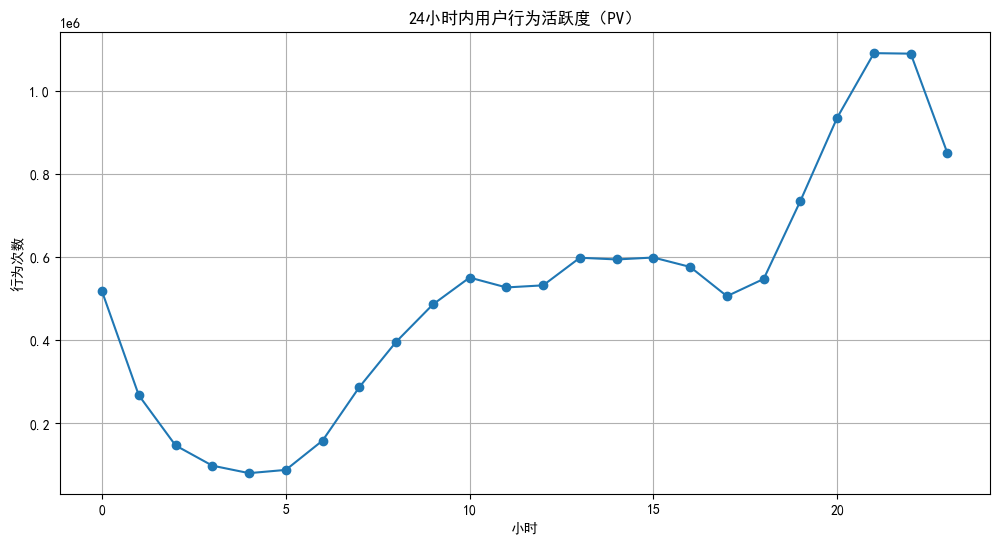

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 读取数据，文件自带表头，所以不要写 header=None
df = pd.read_csv('tianchi_mobile_recommend_train_user.csv', low_memory=False)

# 查看列名和前几行
print("列名：", list(df.columns))
print(df.head())

# 时间列是字符串格式，例如 2014-12-06 02，不能加 unit='s'
df['time'] = pd.to_datetime(df['time'], errors='coerce')

# 提取小时
df['hour'] = df['time'].dt.hour

# 按小时统计行为次数 PV
pv_per_hour = df.groupby('hour').size()

# 画图
pv_per_hour.plot(kind='line', figsize=(12, 6), marker='o')
plt.title('24小时内用户行为活跃度（PV）')
plt.xlabel('小时')
plt.ylabel('行为次数')
plt.grid(True)
plt.savefig('hourly_pv_line.png', dpi=150, bbox_inches='tight')
plt.show()

各行为数量：
behavior_type
浏览    11550581
收藏      242556
加购      343564
购买      120205
Name: count, dtype: int64


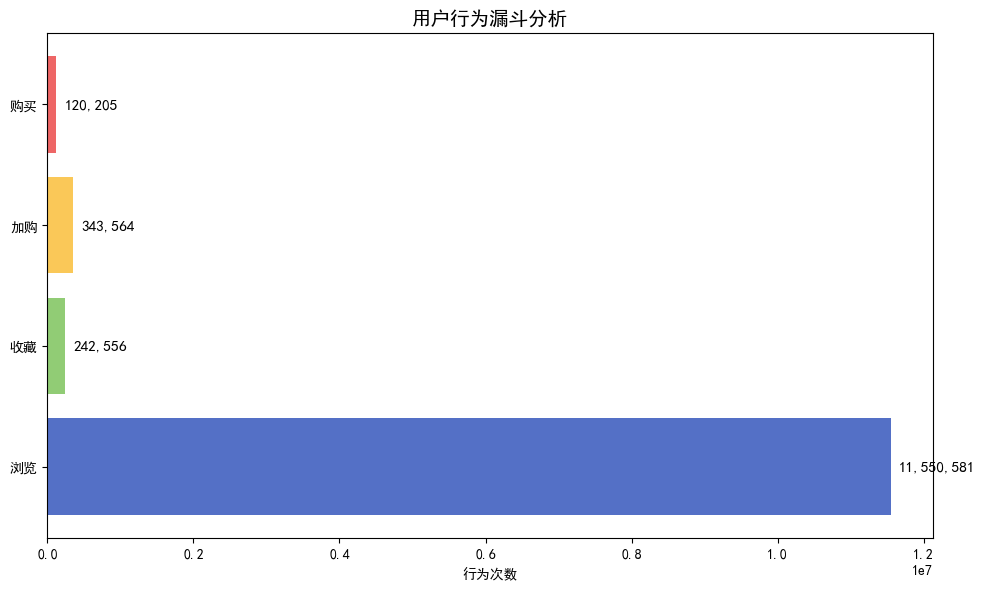


收藏转化率: 2.10%
加购转化率: 2.97%
购买转化率: 1.04%


In [8]:
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 统计各行为类型的数量
behavior_count = df['behavior_type'].value_counts().sort_index()

# 给行为类型加上中文标签
behavior_labels = {1: '浏览', 2: '收藏', 3: '加购', 4: '购买'}
behavior_count.index = behavior_count.index.map(behavior_labels)

print("各行为数量：")
print(behavior_count)

# 画漏斗图（用横向条形图模拟）
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#5470c6', '#91cc75', '#fac858', '#ee6666']
bars = ax.barh(behavior_count.index, behavior_count.values, color=colors)

# 在条形上标注具体数值
for bar, val in zip(bars, behavior_count.values):
    ax.text(bar.get_width() + max(behavior_count.values) * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f'{val:,}', va='center', fontsize=11)

ax.set_title('用户行为漏斗分析', fontsize=14)
ax.set_xlabel('行为次数')
plt.tight_layout()
plt.show()

# 计算转化率
pv = behavior_count.get('浏览', 0)
fav = behavior_count.get('收藏', 0)
cart = behavior_count.get('加购', 0)
buy = behavior_count.get('购买', 0)

print(f"\n收藏转化率: {fav/pv*100:.2f}%")
print(f"加购转化率: {cart/pv*100:.2f}%")
print(f"购买转化率: {buy/pv*100:.2f}%")

浏览量最高的前10个商品类目：
item_category
1863     371738
13230    342694
5027     320870
5894     314784
6513     281370
5399     268639
11279    177961
2825     155949
5232     135506
10894    131221
Name: count, dtype: int64


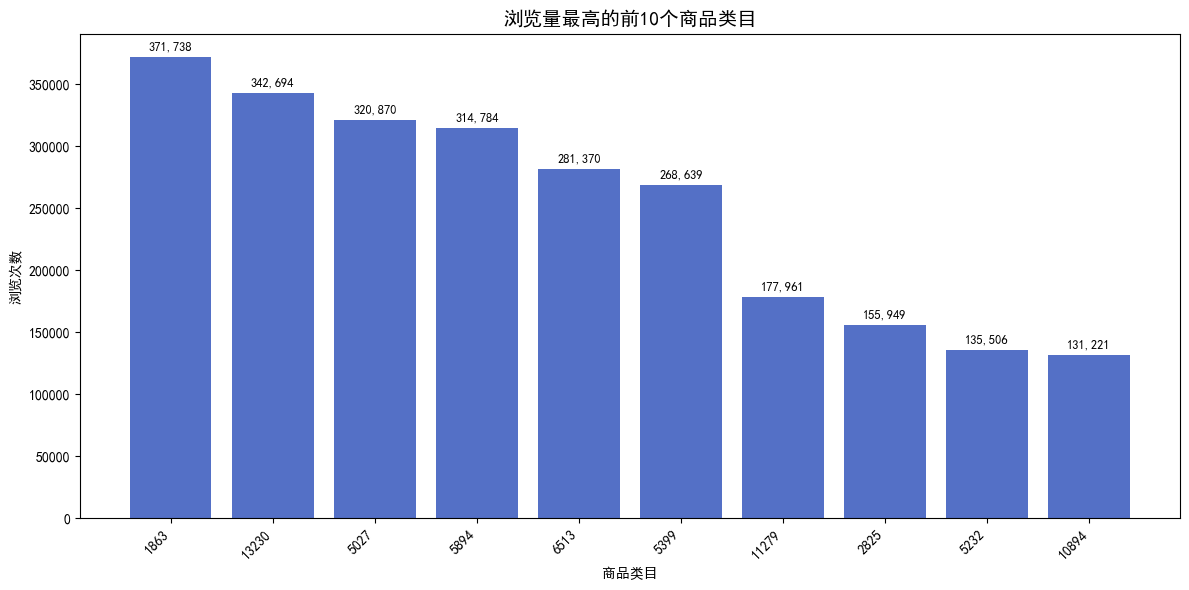

In [9]:
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 统计被浏览最多的前10个商品类目
top_categories = df[df['behavior_type'] == 1]['item_category'].value_counts().head(10)

print("浏览量最高的前10个商品类目：")
print(top_categories)

# 画柱状图
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(range(len(top_categories)), top_categories.values, color='#5470c6')

# 设置x轴标签为类目名称（倒序显示，让最高的在左边）
ax.set_xticks(range(len(top_categories)))
ax.set_xticklabels(top_categories.index, rotation=45, ha='right')

# 在柱子上标注数值
for bar, val in zip(bars, top_categories.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + max(top_categories.values) * 0.01,
            f'{val:,}', ha='center', va='bottom', fontsize=9)

ax.set_title('浏览量最高的前10个商品类目', fontsize=14)
ax.set_xlabel('商品类目')
ax.set_ylabel('浏览次数')
plt.tight_layout()
plt.savefig('funnel_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

各时段购买次数：
hour
0     4845
1     1703
2      806
3      504
4      397
5      476
6     1023
7     1938
8     3586
9     5707
10    7317
11    7086
12    6956
13    7717
14    7207
15    7312
16    6930
17    5298
18    5140
19    6352
20    7872
21    8829
22    8845
23    6359
dtype: int64


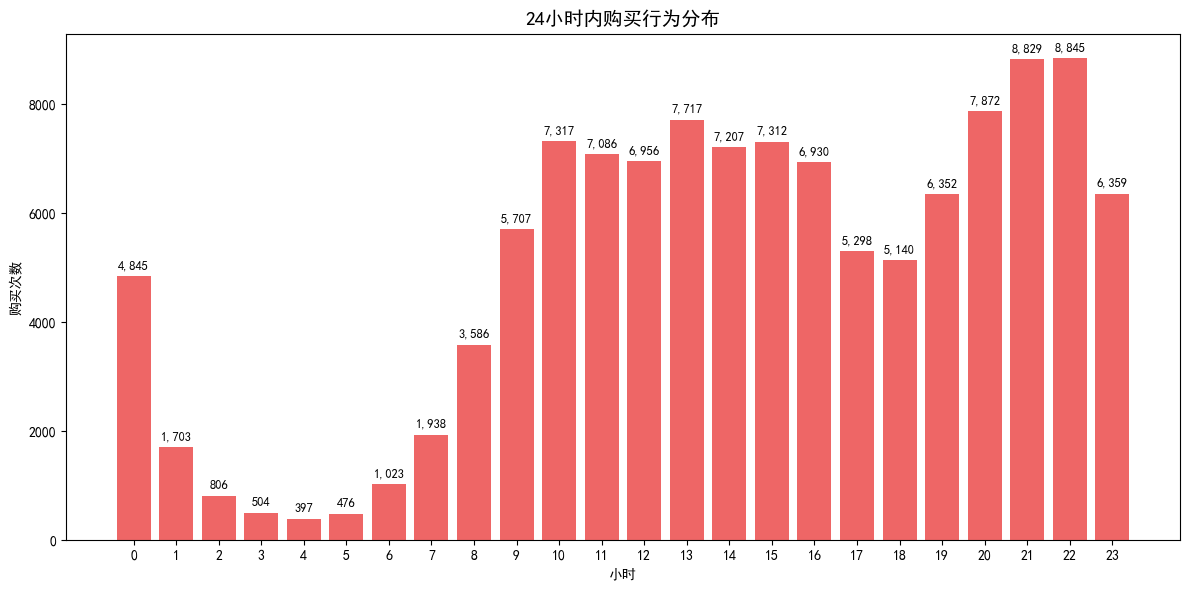

In [10]:
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 筛选出购买行为（behavior_type == 4）
buy_df = df[df['behavior_type'] == 4].copy()
buy_df['hour'] = buy_df['time'].dt.hour

# 按小时统计购买次数
buy_per_hour = buy_df.groupby('hour').size()

print("各时段购买次数：")
print(buy_per_hour)

# 画柱状图
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(buy_per_hour.index, buy_per_hour.values, color='#ee6666')

# 标注数值
for bar, val in zip(bars, buy_per_hour.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + max(buy_per_hour.values) * 0.01,
            f'{val:,}', ha='center', va='bottom', fontsize=9)

ax.set_title('24小时内购买行为分布', fontsize=14)
ax.set_xlabel('小时')
ax.set_ylabel('购买次数')
ax.set_xticks(range(24))
plt.tight_layout()
plt.savefig('top_category_bar.png', dpi=150, bbox_inches='tight')
plt.show()